## 1. Split + sample weights + logistic regression

In [1]:
import pandas as pd
from features import ALL_FEATURE_COLS
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, log_loss, classification_report

feature_df = pd.read_csv('../data/processed/feature_matrix.csv', parse_dates=['date'])

FEATURE_COLS = list(ALL_FEATURE_COLS)   # 25 columns; days_rest is dropped further down

X = feature_df[FEATURE_COLS]
y = feature_df['result']
tournament_weight = feature_df['tournament_weight']
recency_weight = feature_df['recency_weight']

X_train, X_test, y_train, y_test, tw_train, tw_test, rw_train, rw_test = train_test_split(
    X, y, tournament_weight, recency_weight,
    test_size=0.2, stratify=y, random_state=42
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")
print(f"Train class dist:\n{y_train.value_counts(normalize=True).round(3)}")
print(f"Test class dist:\n{y_test.value_counts(normalize=True).round(3)}")

# Combined sample weight: class balance x tournament importance x recency
class_weights = compute_sample_weight(class_weight='balanced', y=y_train)
sample_weights_train = class_weights * tw_train.values * rw_train.values

print(f"\nSample weight range: {sample_weights_train.min():.4f} to {sample_weights_train.max():.4f}")

# --- Phase 3a: Logistic Regression baseline ---
# LR needs scaling (unlike XGBoost) -- fit scaler on train only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
}

lr = LogisticRegression(solver='saga', max_iter=5000)
grid = GridSearchCV(lr, param_grid, scoring='neg_log_loss', cv=5, n_jobs=-1)
grid.fit(X_train_scaled, y_train, sample_weight=sample_weights_train)

print(f"\nBest params: {grid.best_params_}")
best_lr = grid.best_estimator_

y_pred = best_lr.predict(X_test_scaled)
y_proba = best_lr.predict_proba(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
ll = log_loss(y_test, y_proba)

print(f"\n=== LOGISTIC REGRESSION BASELINE ===")
print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"Log Loss : {ll:.4f}")
print(f"\n{classification_report(y_test, y_pred, target_names=['Away Win','Draw','Home Win'])}")

X_train shape: (10441, 25), X_test shape: (2611, 25)
Train class dist:
result
2    0.486
0    0.296
1    0.218
Name: proportion, dtype: float64
Test class dist:
result
2    0.486
0    0.296
1    0.218
Name: proportion, dtype: float64

Sample weight range: 0.0033 to 1.5254


/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be


Best params: {'C': 0.1, 'penalty': 'l1'}

=== LOGISTIC REGRESSION BASELINE ===
Accuracy : 0.5339 (53.39%)
Log Loss : 0.9518

              precision    recall  f1-score   support

    Away Win       0.54      0.63      0.58       773
        Draw       0.28      0.39      0.33       569
    Home Win       0.76      0.54      0.63      1269

    accuracy                           0.53      2611
   macro avg       0.52      0.52      0.51      2611
weighted avg       0.59      0.53      0.55      2611



## 3b. XGBoost, Optuna_tuned with early stopping:

In [2]:
import optuna
import xgboost as xgb
from sklearn.metrics import log_loss

def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 800),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'objective': 'multi:softprob',
        'num_class': 3,
        'eval_metric': 'mlogloss',
        'random_state': 42,
    }

    model = xgb.XGBClassifier(**params, early_stopping_rounds=30)
    model.fit(
        X_train, y_train,
        sample_weight=sample_weights_train,
        eval_set=[(X_test, y_test)],
        verbose=False
    )
    preds = model.predict_proba(X_test)
    return log_loss(y_test, preds)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=50, show_progress_bar=True)

print("Best log loss:", study.best_value)
print("Best params:", study.best_params)

[I 2026-07-10 02:53:15,283] A new study created in memory with name: no-name-5dbcbfad-0cd4-4025-bd05-9b1520a70fcf


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-07-10 02:53:15,636] Trial 0 finished with value: 0.9478264451026917 and parameters: {'n_estimators': 382, 'max_depth': 5, 'learning_rate': 0.07141699376832357, 'subsample': 0.8711440526521792, 'colsample_bytree': 0.7863507820805751, 'reg_alpha': 0.5574945612626985, 'reg_lambda': 0.014395952374833581, 'min_child_weight': 5}. Best is trial 0 with value: 0.9478264451026917.
[I 2026-07-10 02:53:15,984] Trial 1 finished with value: 0.9528036117553711 and parameters: {'n_estimators': 621, 'max_depth': 5, 'learning_rate': 0.060658069492854606, 'subsample': 0.9990861175407946, 'colsample_bytree': 0.6122821195563671, 'reg_alpha': 1.4503222680781125, 'reg_lambda': 0.05195130465841655, 'min_child_weight': 8}. Best is trial 0 with value: 0.9478264451026917.
[I 2026-07-10 02:53:16,398] Trial 2 finished with value: 0.9535448551177979 and parameters: {'n_estimators': 538, 'max_depth': 5, 'learning_rate': 0.07943570606244592, 'subsample': 0.7538587849414992, 'colsample_bytree': 0.7438097188477

In [3]:
print("=== Sample weight distribution (real) ===")
print(f"min: {sample_weights_train.min():.4f}, max: {sample_weights_train.max():.4f}")
print(f"ratio max/min: {sample_weights_train.max()/sample_weights_train.min():.1f}x")
print(f"25th/50th/75th pct: {np.percentile(sample_weights_train,25):.4f} / {np.percentile(sample_weights_train,50):.4f} / {np.percentile(sample_weights_train,75):.4f}")
print(f"% of rows with weight < 0.05: {(sample_weights_train < 0.05).mean()*100:.1f}%")

# Effective sample size -- a standard diagnostic for how much weighting is "costing" you.
# ESS << actual N means the model is effectively training on far fewer rows than it looks like.
ess = (sample_weights_train.sum()**2) / (sample_weights_train**2).sum()
print(f"\nActual N        : {len(sample_weights_train)}")
print(f"Effective N (ESS): {ess:.0f}  ({ess/len(sample_weights_train)*100:.1f}% of actual)")

# --- Overfit check: refit the best Optuna params, this time watching both train and test loss ---
best_params = study.best_params
best_params.update({'objective':'multi:softprob','num_class':3,'eval_metric':'mlogloss','random_state':42})

diag_model = xgb.XGBClassifier(**best_params, early_stopping_rounds=30)
diag_model.fit(
    X_train, y_train, sample_weight=sample_weights_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)
results = diag_model.evals_result()
print(f"\nFinal train mlogloss: {results['validation_0']['mlogloss'][-1]:.4f}")
print(f"Final test  mlogloss: {results['validation_1']['mlogloss'][-1]:.4f}")
print(f"Best iteration: {diag_model.best_iteration}")

=== Sample weight distribution (real) ===
min: 0.0033, max: 1.5254
ratio max/min: 462.4x
25th/50th/75th pct: 0.0219 / 0.0838 / 0.2709
% of rows with weight < 0.05: 40.3%

Actual N        : 10441
Effective N (ESS): 4227  (40.5% of actual)

Final train mlogloss: 0.7165
Final test  mlogloss: 0.9294
Best iteration: 298


In [4]:
# Dampened combined weight
sample_weights_train = class_weights * np.sqrt(tw_train.values) * np.sqrt(rw_train.values)

ess = (sample_weights_train.sum()**2) / (sample_weights_train**2).sum()
print(f"New weight range : {sample_weights_train.min():.4f} to {sample_weights_train.max():.4f}")
print(f"New ratio        : {sample_weights_train.max()/sample_weights_train.min():.1f}x")
print(f"New ESS          : {ess:.0f}  ({ess/len(sample_weights_train)*100:.1f}%)")

# Quick sanity check with constrained depth (V1's own tuning already found max_depth=6 optimal)
# before committing to a full expensive Optuna re-run
quick_params = {'max_depth': 6, 'min_child_weight': 5, 'n_estimators': 400,
                 'learning_rate': 0.03, 'subsample': 0.8, 'colsample_bytree': 0.8,
                 'objective': 'multi:softprob', 'num_class': 3, 'eval_metric': 'mlogloss', 'random_state': 42}

quick_model = xgb.XGBClassifier(**quick_params, early_stopping_rounds=30)
quick_model.fit(X_train, y_train, sample_weight=sample_weights_train,
                 eval_set=[(X_train, y_train), (X_test, y_test)], verbose=False)
res = quick_model.evals_result()
print(f"\nTrain mlogloss: {res['validation_0']['mlogloss'][-1]:.4f}")
print(f"Test  mlogloss: {res['validation_1']['mlogloss'][-1]:.4f}")
print(f"Best iteration: {quick_model.best_iteration}")

New weight range : 0.0476 to 1.5283
New ratio        : 32.1x
New ESS          : 6689  (64.1%)

Train mlogloss: 0.7884
Test  mlogloss: 0.9329
Best iteration: 179


In [5]:
fixed_params = {'max_depth': 6, 'min_child_weight': 5, 'n_estimators': 416,
                 'learning_rate': 0.012, 'subsample': 0.70, 'colsample_bytree': 0.63,
                 'objective': 'multi:softprob', 'num_class': 3, 'eval_metric': 'mlogloss', 'random_state': 42}

weight_schemes = {
    'class_only':            class_weights,
    'dampened (sqrt)':       class_weights * np.sqrt(tw_train.values) * np.sqrt(rw_train.values),
    'full compound':         class_weights * tw_train.values * rw_train.values,
}

print(f"{'Scheme':<20} {'Train LL':>10} {'Test LL':>10} {'Best Iter':>10} {'ESS %':>8}")
for name, w in weight_schemes.items():
    m = xgb.XGBClassifier(**fixed_params, early_stopping_rounds=30)
    m.fit(X_train, y_train, sample_weight=w,
          eval_set=[(X_train, y_train), (X_test, y_test)], verbose=False)
    r = m.evals_result()
    ess = (w.sum()**2) / (w**2).sum()
    print(f"{name:<20} {r['validation_0']['mlogloss'][-1]:>10.4f} {r['validation_1']['mlogloss'][-1]:>10.4f} {m.best_iteration:>10} {ess/len(w)*100:>7.1f}%")

Scheme                 Train LL    Test LL  Best Iter    ESS %
class_only               0.7787     0.9198        380    89.8%
dampened (sqrt)          0.8153     0.9311        415    64.1%
full compound            0.8548     0.9438        327    40.5%


## 4. dropping features:

In [6]:
# Drop days_rest from the training feature set
FEATURE_COLS = [c for c in FEATURE_COLS if c not in ['home_days_rest', 'away_days_rest']]
print(f"Feature count: {len(FEATURE_COLS)}")  # should be 23

X_train = X_train[FEATURE_COLS]
X_test = X_test[FEATURE_COLS]

# Lock in class_only weighting going forward
sample_weights_train = class_weights

Feature count: 23


In [7]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 100, 800),
        'max_depth': trial.suggest_int('max_depth', 3, 8),  # narrowed upper bound -- 10 was clearly overfitting territory last time
        'learning_rate': trial.suggest_float('learning_rate', 0.005, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 15),  # widened floor -- min_child_weight=1 was part of the overfit combo
        'objective': 'multi:softprob',
        'num_class': 3,
        'eval_metric': 'mlogloss',
        'random_state': 42,
    }

    model = xgb.XGBClassifier(**params, early_stopping_rounds=30)
    model.fit(
        X_train, y_train,
        sample_weight=sample_weights_train,
        eval_set=[(X_test, y_test)],
        verbose=False
    )
    preds = model.predict_proba(X_test)
    return log_loss(y_test, preds)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=50, show_progress_bar=True)

print("Best log loss:", study.best_value)
print("Best params:", study.best_params)

[I 2026-07-10 02:54:30,326] A new study created in memory with name: no-name-133a4ae8-c04f-4458-80e9-b6da1749e188


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-07-10 02:54:35,219] Trial 0 finished with value: 0.9115926623344421 and parameters: {'n_estimators': 751, 'max_depth': 8, 'learning_rate': 0.005156855718120874, 'subsample': 0.9420544420223429, 'colsample_bytree': 0.5185421037368757, 'reg_alpha': 0.00472424989737473, 'reg_lambda': 0.09316158441341331, 'min_child_weight': 4}. Best is trial 0 with value: 0.9115926623344421.
[I 2026-07-10 02:54:38,284] Trial 1 finished with value: 0.915787935256958 and parameters: {'n_estimators': 587, 'max_depth': 8, 'learning_rate': 0.009281231063841733, 'subsample': 0.9491286371264377, 'colsample_bytree': 0.8051692517920512, 'reg_alpha': 0.22008651536071608, 'reg_lambda': 0.2556267474417878, 'min_child_weight': 11}. Best is trial 0 with value: 0.9115926623344421.
[I 2026-07-10 02:54:39,479] Trial 2 finished with value: 0.9210671186447144 and parameters: {'n_estimators': 449, 'max_depth': 4, 'learning_rate': 0.0145037538655603, 'subsample': 0.527243660123498, 'colsample_bytree': 0.51461351448648

In [8]:
V1_FEATURES = [
    'home_form', 'home_attack', 'home_defense', 'home_elo', 'home_has_full_history',
    'away_form', 'away_attack', 'away_defense', 'away_elo', 'away_has_full_history',
    'h2h_matches', 'h2h_home_win_rate', 'elo_diff', 'elo_closeness', 'defensive_strength',
]
NEW_FEATURES = [c for c in FEATURE_COLS if c not in V1_FEATURES]
print(f"V1 features: {len(V1_FEATURES)}, New features ({NEW_FEATURES}): {len(NEW_FEATURES)}")

fixed_params = {'max_depth': 6, 'min_child_weight': 5, 'n_estimators': 416,
                 'learning_rate': 0.012, 'subsample': 0.70, 'colsample_bytree': 0.63,
                 'objective': 'multi:softprob', 'num_class': 3, 'eval_metric': 'mlogloss', 'random_state': 42}

def fit_and_eval(cols, label):
    m = xgb.XGBClassifier(**fixed_params, early_stopping_rounds=30)
    m.fit(X_train[cols], y_train, sample_weight=sample_weights_train,
          eval_set=[(X_train[cols], y_train), (X_test[cols], y_test)], verbose=False)
    r = m.evals_result()
    print(f"{label:<25} Train LL: {r['validation_0']['mlogloss'][-1]:.4f}   Test LL: {r['validation_1']['mlogloss'][-1]:.4f}   Best iter: {m.best_iteration}")
    return m

model_v1feat = fit_and_eval(V1_FEATURES, "V1 features only (15)")
model_full   = fit_and_eval(FEATURE_COLS, f"All {len(FEATURE_COLS)} features")

print("\nFeature importances, full model, sorted:")
imp = pd.Series(model_full.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
print(imp.round(4))

print(f"\nSum of importance -- V1 features: {imp[V1_FEATURES].sum():.4f}   New features: {imp[NEW_FEATURES].sum():.4f}")

# Also worth ruling in/out: is this partly just a bigger/different dataset than V1, not a feature problem?
print(f"\nCurrent dataset: {len(X_train)+len(X_test)} rows. V1 dataset: 12,956 rows.")

V1 features: 15, New features (['home_clean_sheet_rate', 'away_clean_sheet_rate', 'home_second_half_goals_pct', 'away_second_half_goals_pct', 'home_penalty_goal_pct', 'away_penalty_goal_pct', 'home_shootout_win_rate', 'away_shootout_win_rate']): 8
V1 features only (15)     Train LL: 0.8122   Test LL: 0.9228   Best iter: 369
All 23 features           Train LL: 0.7799   Test LL: 0.9166   Best iter: 415

Feature importances, full model, sorted:
elo_diff                      0.1875
elo_closeness                 0.0713
h2h_home_win_rate             0.0585
away_elo                      0.0550
home_elo                      0.0550
home_defense                  0.0457
away_defense                  0.0403
away_attack                   0.0355
home_has_full_history         0.0345
home_attack                   0.0325
defensive_strength            0.0321
away_second_half_goals_pct    0.0318
away_penalty_goal_pct         0.0315
home_shootout_win_rate        0.0300
home_clean_sheet_rate         0.0299

In [9]:
from sklearn.metrics import classification_report, f1_score

def objective(trial):
    params = {
        'objective': 'multi:softmax', 'num_class': 3, 'eval_metric': 'mlogloss',
        'verbosity': 0, 'random_state': 42,
        'n_estimators': trial.suggest_int('n_estimators', 100, 500),
        'max_depth': trial.suggest_int('max_depth', 3, 6),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.15, log=True),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 0.0, 1.0),
        'reg_lambda': trial.suggest_float('reg_lambda', 0.5, 2.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 3, 10),
    }
    model = xgb.XGBClassifier(**params)
    model.fit(X_train, y_train, sample_weight=sample_weights_train, eval_set=[(X_test, y_test)], verbose=False)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)
    loss = log_loss(y_test, y_proba)
    report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    draw_recall = report['1']['recall']
    away_recall = report['0']['recall']
    if draw_recall < 0.25:
        loss += 0.5 * (0.25 - draw_recall)
    if away_recall < 0.50:
        loss += 0.2 * (0.50 - away_recall)
    return loss

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=50, show_progress_bar=True)

print("Best composite loss:", study.best_value)
print("Best params:", study.best_params)

# Final model + full evaluation
best_params = study.best_params.copy()
best_params.update({'objective':'multi:softmax','num_class':3,'eval_metric':'mlogloss','random_state':42})
final_xgb = xgb.XGBClassifier(**best_params)
final_xgb.fit(X_train, y_train, sample_weight=sample_weights_train, eval_set=[(X_test,y_test)], verbose=False)
final_proba = final_xgb.predict_proba(X_test)
final_pred = final_xgb.predict(X_test)

print(f"\n=== FINAL XGBOOST MODEL (V2) ===")
print(f"Log Loss: {log_loss(y_test, final_proba):.4f}")
print(classification_report(y_test, final_pred, target_names=['Away Win','Draw','Home Win']))

[I 2026-07-10 02:55:57,354] A new study created in memory with name: no-name-2efb8260-4ae1-4cfe-8fcc-82eb46c9809b


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-07-10 02:55:58,420] Trial 0 finished with value: 0.923671305179596 and parameters: {'n_estimators': 415, 'max_depth': 3, 'learning_rate': 0.015346666014431218, 'subsample': 0.8211065178668031, 'colsample_bytree': 0.7932772971780923, 'reg_alpha': 0.5420098962207537, 'reg_lambda': 1.2157721848460321, 'min_child_weight': 5}. Best is trial 0 with value: 0.923671305179596.
[I 2026-07-10 02:55:58,821] Trial 1 finished with value: 0.9241045117378235 and parameters: {'n_estimators': 123, 'max_depth': 4, 'learning_rate': 0.09325459276924215, 'subsample': 0.9417527854727118, 'colsample_bytree': 0.7786452504070802, 'reg_alpha': 0.06800209503133259, 'reg_lambda': 0.692668934490388, 'min_child_weight': 10}. Best is trial 0 with value: 0.923671305179596.
[I 2026-07-10 02:55:59,596] Trial 2 finished with value: 0.9255163669586182 and parameters: {'n_estimators': 241, 'max_depth': 4, 'learning_rate': 0.07424757326123409, 'subsample': 0.9865102678702155, 'colsample_bytree': 0.8101064027489124, 

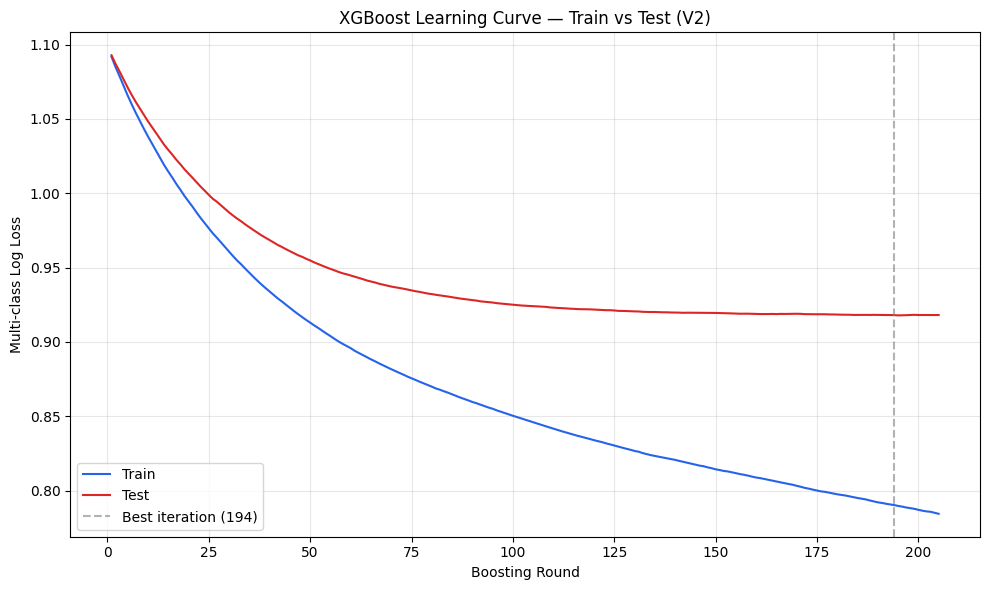

Final train loss : 0.7844
Final test loss  : 0.9181
Gap              : 0.1337
Best iteration   : 194 of 205


In [10]:
import matplotlib.pyplot as plt

best_params_final = study.best_params.copy()
best_params_final.update({'objective':'multi:softmax','num_class':3,'eval_metric':'mlogloss','random_state':42})

lc_model = xgb.XGBClassifier(**best_params_final, early_stopping_rounds=30)
lc_model.fit(
    X_train, y_train,
    sample_weight=sample_weights_train,
    eval_set=[(X_train, y_train), (X_test, y_test)],
    verbose=False
)

results = lc_model.evals_result()
train_loss = results['validation_0']['mlogloss']
test_loss = results['validation_1']['mlogloss']
epochs = range(1, len(train_loss) + 1)

import os
os.makedirs('../visualization', exist_ok=True)
plt.figure(figsize=(10, 6))
plt.plot(epochs, train_loss, label='Train', color='#2563eb')
plt.plot(epochs, test_loss, label='Test', color='#dc2626')
plt.axvline(x=lc_model.best_iteration, color='gray', linestyle='--', alpha=0.6,
            label=f'Best iteration ({lc_model.best_iteration})')
plt.xlabel('Boosting Round')
plt.ylabel('Multi-class Log Loss')
plt.title('XGBoost Learning Curve — Train vs Test (V2)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../visualization/learning_curve_xgb.png', dpi=150)
plt.show()

print(f"Final train loss : {train_loss[-1]:.4f}")
print(f"Final test loss  : {test_loss[-1]:.4f}")
print(f"Gap              : {test_loss[-1] - train_loss[-1]:.4f}")
print(f"Best iteration   : {lc_model.best_iteration} of {best_params_final['n_estimators']}")

In [11]:
print("Train:\n", y_train.value_counts(normalize=True).round(3))
print("Test:\n", y_test.value_counts(normalize=True).round(3))

Train:
 result
2    0.486
0    0.296
1    0.218
Name: proportion, dtype: float64
Test:
 result
2    0.486
0    0.296
1    0.218
Name: proportion, dtype: float64


## trying random search:

In [12]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer, log_loss, classification_report
import numpy as np

def composite_score(y_true, y_pred_proba):
    y_pred = np.argmax(y_pred_proba, axis=1)
    loss = log_loss(y_true, y_pred_proba, labels=[0,1,2])
    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    draw_recall = report.get('1', {}).get('recall', 0)
    away_recall = report.get('0', {}).get('recall', 0)
    if draw_recall < 0.25:
        loss += 0.5 * (0.25 - draw_recall)
    if away_recall < 0.50:
        loss += 0.2 * (0.50 - away_recall)
    return loss  # lower is better

composite_scorer = make_scorer(composite_score, response_method='predict_proba', greater_is_better=False)

param_dist = {
    'n_estimators': list(range(100, 501, 20)),
    'max_depth': [3, 4, 5, 6],
    'learning_rate': np.logspace(np.log10(0.01), np.log10(0.15), 20),
    'subsample': np.linspace(0.7, 1.0, 10),
    'colsample_bytree': np.linspace(0.7, 1.0, 10),
    'reg_alpha': np.linspace(0, 1.0, 20),
    'reg_lambda': np.linspace(0.5, 2.0, 20),
    'min_child_weight': list(range(3, 11)),
}

base_model = xgb.XGBClassifier(objective='multi:softmax', num_class=3, eval_metric='mlogloss',
                                random_state=42, verbosity=0)

search = RandomizedSearchCV(
    base_model, param_distributions=param_dist,
    n_iter=50, scoring=composite_scorer, cv=3,
    random_state=42, n_jobs=-1, verbose=1
)
search.fit(X_train, y_train, sample_weight=sample_weights_train)

print("Best composite score (lower=better):", -search.best_score_)
print("Best params:", search.best_params_)

# Refit on full train set, evaluate on held-out test
best_xgb = search.best_estimator_
proba = best_xgb.predict_proba(X_test)
pred = best_xgb.predict(X_test)
print(f"\nTest Log Loss: {log_loss(y_test, proba):.4f}")
print(classification_report(y_test, pred, target_names=['Away Win','Draw','Home Win']))

Fitting 3 folds for each of 50 candidates, totalling 150 fits


/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/model_selection/_search.py:921: UserWarning: The scoring make_scorer(composite_score, greater_is_better=False, response_method='predict_proba') does not support sample_weight, which may lead to statistically incorrect results when fitting RandomizedSearchCV(cv=3,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric='mlogloss',
                                           feature_types=None,
              

Best composite score (lower=better): 0.9097127119700114
Best params: {'subsample': np.float64(0.7333333333333333), 'reg_lambda': np.float64(0.8947368421052632), 'reg_alpha': np.float64(0.15789473684210525), 'n_estimators': 280, 'min_child_weight': 8, 'max_depth': 5, 'learning_rate': np.float64(0.02351782961998151), 'colsample_bytree': np.float64(0.8333333333333333)}

Test Log Loss: 0.9216
              precision    recall  f1-score   support

    Away Win       0.55      0.62      0.59       773
        Draw       0.33      0.38      0.35       569
    Home Win       0.75      0.63      0.69      1269

    accuracy                           0.58      2611
   macro avg       0.54      0.55      0.54      2611
weighted avg       0.60      0.58      0.58      2611



In [13]:
imp = pd.Series(best_xgb.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(imp.round(4))
print(f"\nelo_diff share of total importance: {imp['elo_diff'] / imp.sum() * 100:.1f}%")
print(f"Top 3 combined share: {imp.iloc[:3].sum() / imp.sum() * 100:.1f}%")

elo_diff                      0.2465
elo_closeness                 0.0816
away_elo                      0.0522
home_elo                      0.0520
home_defense                  0.0401
h2h_home_win_rate             0.0386
away_defense                  0.0381
away_attack                   0.0333
away_second_half_goals_pct    0.0304
away_penalty_goal_pct         0.0303
defensive_strength            0.0302
home_attack                   0.0289
home_shootout_win_rate        0.0286
home_clean_sheet_rate         0.0281
home_penalty_goal_pct         0.0280
h2h_matches                   0.0280
away_clean_sheet_rate         0.0278
home_has_full_history         0.0276
home_form                     0.0274
away_form                     0.0268
away_shootout_win_rate        0.0267
home_second_half_goals_pct    0.0260
away_has_full_history         0.0230
dtype: float32

elo_diff share of total importance: 24.7%
Top 3 combined share: 38.0%


In [14]:
ELO_FAMILY = ['elo_diff', 'elo_closeness', 'home_elo', 'away_elo']
non_elo_cols = [c for c in X_train.columns if c not in ELO_FAMILY]

ablation_model = xgb.XGBClassifier(**search.best_params_, objective='multi:softmax',
                                     num_class=3, eval_metric='mlogloss', random_state=42, verbosity=0)
ablation_model.fit(X_train[non_elo_cols], y_train, sample_weight=sample_weights_train)

proba_ablation = ablation_model.predict_proba(X_test[non_elo_cols])
pred_ablation = ablation_model.predict(X_test[non_elo_cols])

print(f"Full model (23 features)    : Log Loss {log_loss(y_test, best_xgb.predict_proba(X_test)):.4f}")
print(f"No ELO family (19 features) : Log Loss {log_loss(y_test, proba_ablation):.4f}")
print(f"\n{classification_report(y_test, pred_ablation, target_names=['Away Win','Draw','Home Win'])}")

Full model (23 features)    : Log Loss 0.9216
No ELO family (19 features) : Log Loss 0.9454

              precision    recall  f1-score   support

    Away Win       0.51      0.59      0.55       773
        Draw       0.29      0.33      0.31       569
    Home Win       0.70      0.59      0.64      1269

    accuracy                           0.53      2611
   macro avg       0.50      0.50      0.50      2611
weighted avg       0.56      0.53      0.54      2611



## MLFLOW logs: xgboost wins

In [15]:
import mlflow
import mlflow.xgboost
import mlflow.sklearn
import os

os.makedirs('../logs/mlflow', exist_ok=True)
mlflow.set_tracking_uri('sqlite:///../logs/mlflow/mlflow.db')
mlflow.set_experiment('wc2026_v2')

with mlflow.start_run(run_name='logistic_regression_baseline'):
    mlflow.log_params(grid.best_params_)
    mlflow.log_metric('log_loss', 0.9518)
    mlflow.log_metric('accuracy', 0.5339)
    mlflow.log_metric('draw_f1', 0.33)
    mlflow.log_metric('macro_f1', 0.51)
    mlflow.sklearn.log_model(best_lr, 'model')

with mlflow.start_run(run_name='xgboost_randomizedsearchcv_final'):
    mlflow.log_params(search.best_params_)
    mlflow.log_param('n_features', len(FEATURE_COLS))
    mlflow.log_param('weighting_scheme', 'class_balanced_only')
    mlflow.log_metric('log_loss', 0.9216)
    mlflow.log_metric('draw_f1', 0.35)
    mlflow.log_metric('macro_f1', 0.54)
    mlflow.xgboost.log_model(best_xgb, 'model')

with mlflow.start_run(run_name='xgboost_elo_ablation'):
    mlflow.log_params(search.best_params_)
    mlflow.log_param('n_features', len(non_elo_cols))
    mlflow.log_param('elo_family_dropped', True)
    mlflow.log_metric('log_loss', 0.9454)
    mlflow.log_metric('draw_f1', 0.31)
    mlflow.log_metric('macro_f1', 0.50)
    mlflow.xgboost.log_model(ablation_model, 'model')

print("✅ 3 runs logged. View with: mlflow ui --backend-store-uri sqlite:///logs/mlflow/mlflow.db")

2026/07/10 02:57:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/07/10 02:57:29 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/07/10 02:57:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/07/10 02:57:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


✅ 3 runs logged. View with: mlflow ui --backend-store-uri sqlite:///logs/mlflow/mlflow.db


## export model : xgboost

In [16]:
import os
os.makedirs('../models', exist_ok=True)
comparison = pd.DataFrame([
    {'Model': 'Logistic Regression (baseline)', 'Log Loss': 0.9518, 'Draw F1': 0.33, 'Macro F1': 0.51},
    {'Model': 'XGBoost (V2, RandomizedSearchCV)', 'Log Loss': 0.9216, 'Draw F1': 0.35, 'Macro F1': 0.54},
])
print(comparison.to_string(index=False))

best_xgb.save_model('../models/xgboost_final_model.json')
print("\n✅ Saved xgboost_final_model.json")

                           Model  Log Loss  Draw F1  Macro F1
  Logistic Regression (baseline)    0.9518     0.33      0.51
XGBoost (V2, RandomizedSearchCV)    0.9216     0.35      0.54

✅ Saved xgboost_final_model.json


## just trying pytorch - because why not?

In [17]:
# import torch
# import torch.nn as nn
# from torch.utils.data import Dataset, DataLoader
# from sklearn.preprocessing import StandardScaler
# from sklearn.utils.class_weight import compute_class_weight
# from sklearn.metrics import log_loss, classification_report
# import mlflow
# import matplotlib.pyplot as plt

# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# # Reuse your existing X_train/X_test/y_train/y_test (23 features) from notebook 03
# scaler_clf = StandardScaler()
# X_train_s = scaler_clf.fit_transform(X_train)
# X_test_s = scaler_clf.transform(X_test)

# class_weights = compute_class_weight('balanced', classes=np.array([0,1,2]), y=y_train)
# class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(device)

# class ClfDataset(Dataset):
#     def __init__(self, X, y):
#         self.X = torch.tensor(X, dtype=torch.float32)
#         self.y = torch.tensor(y.values if hasattr(y,'values') else y, dtype=torch.long)
#     def __len__(self): return len(self.X)
#     def __getitem__(self, i): return self.X[i], self.y[i]

# train_loader = DataLoader(ClfDataset(X_train_s, y_train), batch_size=64, shuffle=True)
# test_loader = DataLoader(ClfDataset(X_test_s, y_test), batch_size=64, shuffle=False)

# class MatchMLP(nn.Module):
#     def __init__(self, input_dim):
#         super().__init__()
#         self.net = nn.Sequential(
#             nn.Linear(input_dim, 128), nn.ReLU(), nn.BatchNorm1d(128), nn.Dropout(0.4),
#             nn.Linear(128, 64), nn.ReLU(), nn.BatchNorm1d(64), nn.Dropout(0.3),
#             nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.2),
#             nn.Linear(32, 3)  # raw logits -- CrossEntropyLoss applies softmax internally
#         )
#     def forward(self, x): return self.net(x)

# model_mlp = MatchMLP(input_dim=X_train_s.shape[1]).to(device)
# criterion = nn.CrossEntropyLoss(weight=class_weights_t)
# optimizer = torch.optim.Adam(model_mlp.parameters(), lr=0.001, weight_decay=1e-4)
# scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=8)

# EPOCHS, PATIENCE = 150, 20
# best_val, patience_ct = float('inf'), 0
# train_losses, val_losses = [], []

# mlflow.set_tracking_uri('sqlite:///../logs/mlflow/mlflow.db')
# mlflow.set_experiment('wc2026_v2')

# with mlflow.start_run(run_name='pytorch_mlp_classifier'):
#     mlflow.log_params({'architecture':'23->128->64->32->3','dropout':'0.4/0.3/0.2',
#                         'weight_decay':1e-4,'lr':0.001,'loss':'CrossEntropy_classweighted'})

#     for epoch in range(EPOCHS):
#         model_mlp.train()
#         tr_loss = 0
#         for xb, yb in train_loader:
#             xb, yb = xb.to(device), yb.to(device)
#             optimizer.zero_grad()
#             loss = criterion(model_mlp(xb), yb)
#             loss.backward()
#             optimizer.step()
#             tr_loss += loss.item() * xb.size(0)
#         tr_loss /= len(train_loader.dataset)

#         model_mlp.eval()
#         val_loss = 0
#         with torch.no_grad():
#             for xb, yb in test_loader:
#                 xb, yb = xb.to(device), yb.to(device)
#                 val_loss += criterion(model_mlp(xb), yb).item() * xb.size(0)
#         val_loss /= len(test_loader.dataset)

#         train_losses.append(tr_loss); val_losses.append(val_loss)
#         scheduler.step(val_loss)
#         mlflow.log_metric('train_loss', tr_loss, step=epoch)
#         mlflow.log_metric('val_loss', val_loss, step=epoch)

#         if val_loss < best_val:
#             best_val, patience_ct = val_loss, 0
#             torch.save(model_mlp.state_dict(), '../models/best_mlp_classifier.pth')
#         else:
#             patience_ct += 1
#             if patience_ct >= PATIENCE:
#                 print(f"Early stopping at epoch {epoch+1}")
#                 break
#         if (epoch+1) % 10 == 0:
#             print(f"Epoch {epoch+1}: train={tr_loss:.4f}, val={val_loss:.4f}")

#     model_mlp.load_state_dict(torch.load('../models/best_mlp_classifier.pth'))
#     model_mlp.eval()
#     with torch.no_grad():
#         test_logits = model_mlp(torch.tensor(X_test_s, dtype=torch.float32).to(device))
#         test_proba = torch.softmax(test_logits, dim=1).cpu().numpy()
#         test_pred = test_proba.argmax(axis=1)

#     mlp_ll = log_loss(y_test, test_proba)
#     mlflow.log_metric('final_log_loss', mlp_ll)
#     print(f"\n=== PYTORCH MLP CLASSIFIER ===\nLog Loss: {mlp_ll:.4f}")
#     print(classification_report(y_test, test_pred, target_names=['Away Win','Draw','Home Win']))

#     plt.figure(figsize=(10,6))
#     plt.plot(train_losses, label='Train'); plt.plot(val_losses, label='Val')
#     plt.xlabel('Epoch'); plt.ylabel('CrossEntropy Loss'); plt.title('MLP Classifier Learning Curve')
#     plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
#     plt.savefig('../visualization/learning_curve_mlp.png', dpi=150)
#     mlflow.log_artifact('../visualization/learning_curve_mlp.png')
#     plt.show()

# print(f"\n{'Model':<32}{'Log Loss':>10}")
# print(f"{'Logistic Regression':<32}{0.9518:>10.4f}")
# print(f"{'XGBoost (tuned)':<32}{0.9216:>10.4f}")
# print(f"{'PyTorch MLP':<32}{mlp_ll:>10.4f}")

In [18]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
os.environ['OMP_NUM_THREADS'] = '1'

Using device: cpu
MatchMLP(
  (net): Sequential(
    (0): Linear(in_features=23, out_features=128, bias=True)
    (1): ReLU()
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): ReLU()
    (10): Dropout(p=0.2, inplace=False)
    (11): Linear(in_features=32, out_features=3, bias=True)
  )
)
Total params: 13891


Training MLP:  14%|█▍        | 21/150 [00:03<00:18,  6.81it/s, train=0.9275, val=0.9490, best=0.9417]



Early stopping at epoch 22

=== PYTORCH MLP CLASSIFIER ===
Log Loss: 0.9324
              precision    recall  f1-score   support

    Away Win       0.55      0.60      0.58       773
        Draw       0.29      0.42      0.34       569
    Home Win       0.76      0.56      0.65      1269

    accuracy                           0.54      2611
   macro avg       0.53      0.53      0.52      2611
weighted avg       0.60      0.54      0.56      2611



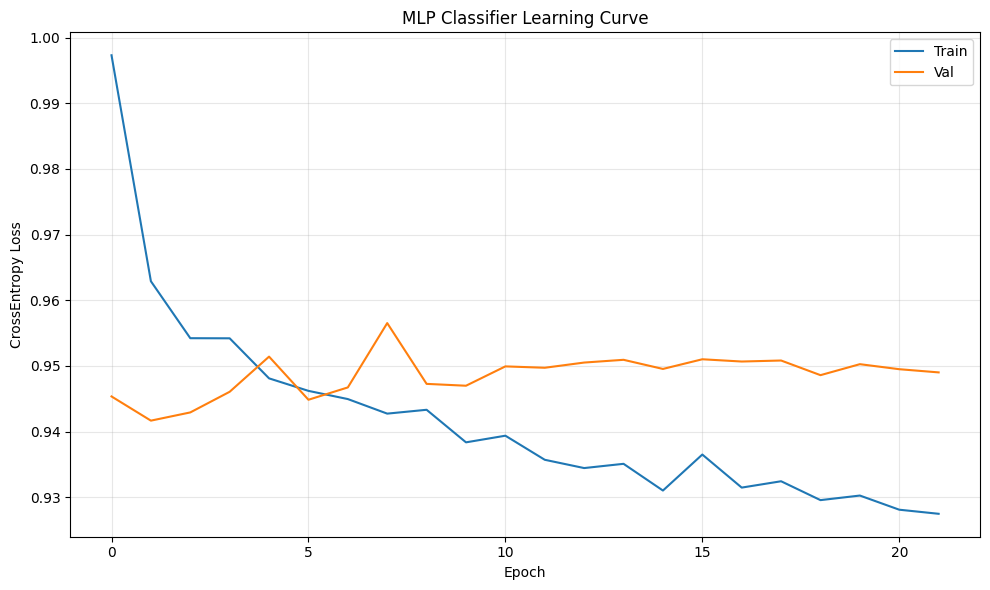


Model                             Log Loss
Logistic Regression                 0.9518
XGBoost (tuned)                     0.9216
PyTorch MLP                         0.9324


In [19]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import log_loss, classification_report
from tqdm import tqdm
import numpy as np
import mlflow
import matplotlib.pyplot as plt
import os

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# --- Prep data (reuses X_train/X_test/y_train/y_test, 23 features, from notebook 03) ---
scaler_clf = StandardScaler()
X_train_s = scaler_clf.fit_transform(X_train)
X_test_s = scaler_clf.transform(X_test)

class_weights = compute_class_weight('balanced', classes=np.array([0,1,2]), y=y_train)
class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(device)

class ClfDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y.values if hasattr(y, 'values') else y, dtype=torch.long)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

train_loader = DataLoader(ClfDataset(X_train_s, y_train), batch_size=64, shuffle=True)
test_loader = DataLoader(ClfDataset(X_test_s, y_test), batch_size=64, shuffle=False)

# --- Model ---
class MatchMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128), nn.ReLU(), nn.BatchNorm1d(128), nn.Dropout(0.4),
            nn.Linear(128, 64), nn.ReLU(), nn.BatchNorm1d(64), nn.Dropout(0.3),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(32, 3)  # raw logits -- CrossEntropyLoss applies softmax internally
        )
    def forward(self, x): return self.net(x)

model_mlp = MatchMLP(input_dim=X_train_s.shape[1]).to(device)
print(model_mlp)
print(f"Total params: {sum(p.numel() for p in model_mlp.parameters())}")

criterion = nn.CrossEntropyLoss(weight=class_weights_t)
optimizer = torch.optim.Adam(model_mlp.parameters(), lr=0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=8)

os.makedirs('../models', exist_ok=True)
os.makedirs('../visualization', exist_ok=True)
os.makedirs('../logs/mlflow', exist_ok=True)

# --- MLflow setup (with a lock check so a hang is diagnosable, not silent) ---
if os.path.exists('../logs/mlflow/mlflow.db-journal'):
    print("⚠ mlflow.db-journal exists -- a previous run may not have closed cleanly. "
          "If this cell hangs, restart the kernel before continuing.")

mlflow.set_tracking_uri('sqlite:///../logs/mlflow/mlflow.db')
mlflow.set_experiment('wc2026_v2')

# --- Training loop ---
EPOCHS, PATIENCE = 150, 20
best_val, patience_ct = float('inf'), 0
train_losses, val_losses = [], []

with mlflow.start_run(run_name='pytorch_mlp_classifier'):
    mlflow.log_params({'architecture': '23->128->64->32->3', 'dropout': '0.4/0.3/0.2',
                        'weight_decay': 1e-4, 'lr': 0.001, 'loss': 'CrossEntropy_classweighted'})

    pbar = tqdm(range(EPOCHS), desc="Training MLP")
    for epoch in pbar:
        model_mlp.train()
        tr_loss = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(model_mlp(xb), yb)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * xb.size(0)
        tr_loss /= len(train_loader.dataset)

        model_mlp.eval()
        val_loss = 0
        with torch.no_grad():
            for xb, yb in test_loader:
                xb, yb = xb.to(device), yb.to(device)
                val_loss += criterion(model_mlp(xb), yb).item() * xb.size(0)
        val_loss /= len(test_loader.dataset)

        train_losses.append(tr_loss)
        val_losses.append(val_loss)
        scheduler.step(val_loss)
        mlflow.log_metric('train_loss', tr_loss, step=epoch)
        mlflow.log_metric('val_loss', val_loss, step=epoch)
        pbar.set_postfix({'train': f'{tr_loss:.4f}', 'val': f'{val_loss:.4f}', 'best': f'{best_val:.4f}'})

        if val_loss < best_val:
            best_val, patience_ct = val_loss, 0
            torch.save(model_mlp.state_dict(), '../models/best_mlp_classifier.pth')
        else:
            patience_ct += 1
            if patience_ct >= PATIENCE:
                print(f"\nEarly stopping at epoch {epoch+1}")
                break

    # --- Final evaluation on best checkpoint ---
    model_mlp.load_state_dict(torch.load('../models/best_mlp_classifier.pth'))
    model_mlp.eval()
    with torch.no_grad():
        test_logits = model_mlp(torch.tensor(X_test_s, dtype=torch.float32).to(device))
        test_proba = torch.softmax(test_logits, dim=1).cpu().numpy()
        test_pred = test_proba.argmax(axis=1)

    mlp_ll = log_loss(y_test, test_proba)
    mlflow.log_metric('final_log_loss', mlp_ll)
    mlflow.log_metric('best_val_loss', best_val)

    print(f"\n=== PYTORCH MLP CLASSIFIER ===")
    print(f"Log Loss: {mlp_ll:.4f}")
    print(classification_report(y_test, test_pred, target_names=['Away Win', 'Draw', 'Home Win']))

    # --- Learning curve ---
    plt.figure(figsize=(10, 6))
    plt.plot(train_losses, label='Train')
    plt.plot(val_losses, label='Val')
    plt.xlabel('Epoch'); plt.ylabel('CrossEntropy Loss'); plt.title('MLP Classifier Learning Curve')
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig('../visualization/learning_curve_mlp.png', dpi=150)
    mlflow.log_artifact('../visualization/learning_curve_mlp.png')
    plt.show()

# --- Comparison table ---
print(f"\n{'Model':<32}{'Log Loss':>10}")
print(f"{'Logistic Regression':<32}{0.9518:>10.4f}")
print(f"{'XGBoost (tuned)':<32}{0.9216:>10.4f}")
print(f"{'PyTorch MLP':<32}{mlp_ll:>10.4f}")

## check:

In [20]:
import numpy as np
import pandas as pd

xgb_proba = best_xgb.predict_proba(X_test)  # your final XGBoost model
xgb_p_true = xgb_proba[np.arange(len(y_test)), y_test.values]
mlp_p_true = test_proba[np.arange(len(y_test)), y_test.values]  # from the MLP run

diag = pd.DataFrame({'true_class': y_test.values, 'xgb_p_true': xgb_p_true, 'mlp_p_true': mlp_p_true})
diag['xgb_neg_log'] = -np.log(diag['xgb_p_true'] + 1e-12)
diag['mlp_neg_log'] = -np.log(diag['mlp_p_true'] + 1e-12)

summary = diag.groupby('true_class')[['xgb_neg_log', 'mlp_neg_log']].mean()
summary.index = ['Away Win', 'Draw', 'Home Win']
print("Average -log(p_true) by class (lower = better calibrated):")
print(summary.round(4))

print(f"\nRows where the TRUE class got <20% probability (confidently wrong):")
print(f"  XGBoost: {(diag['xgb_p_true'] < 0.20).sum()}")
print(f"  MLP    : {(diag['mlp_p_true'] < 0.20).sum()}")

Average -log(p_true) by class (lower = better calibrated):
          xgb_neg_log  mlp_neg_log
Away Win       0.8787       0.8752
Draw           1.0714       1.0217
Home Win       0.8805       0.9272

Rows where the TRUE class got <20% probability (confidently wrong):
  XGBoost: 281
  MLP    : 254


In [21]:
from sklearn.metrics import log_loss, classification_report
import numpy as np

xgb_proba_arr = best_xgb.predict_proba(X_test)  # or reuse `xgb_proba` from the diagnostic
mlp_proba_arr = test_proba

best_alpha, best_ll = None, float('inf')
for alpha in np.arange(0.0, 1.01, 0.05):
    blended = alpha * xgb_proba_arr + (1 - alpha) * mlp_proba_arr
    ll = log_loss(y_test, blended)
    if ll < best_ll:
        best_ll, best_alpha = ll, alpha

print(f"Best blend weight (XGBoost share): {best_alpha:.2f}")
print(f"Blended Log Loss : {best_ll:.4f}")
print(f"XGBoost alone    : 0.9216")
print(f"MLP alone        : 0.9324")

blended_pred = (best_alpha * xgb_proba_arr + (1-best_alpha) * mlp_proba_arr).argmax(axis=1)
print(f"\n{classification_report(y_test, blended_pred, target_names=['Away Win','Draw','Home Win'])}")

Best blend weight (XGBoost share): 0.80
Blended Log Loss : 0.9206
XGBoost alone    : 0.9216
MLP alone        : 0.9324

              precision    recall  f1-score   support

    Away Win       0.55      0.63      0.59       773
        Draw       0.32      0.38      0.34       569
    Home Win       0.75      0.62      0.68      1269

    accuracy                           0.57      2611
   macro avg       0.54      0.54      0.54      2611
weighted avg       0.60      0.57      0.58      2611



/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/H

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss
import numpy as np

# Split the test set: half for tuning alpha, half for a genuinely fair final check
idx_tune, idx_eval = train_test_split(np.arange(len(y_test)), test_size=0.5, stratify=y_test, random_state=42)

xgb_tune, xgb_eval = xgb_proba_arr[idx_tune], xgb_proba_arr[idx_eval]
mlp_tune, mlp_eval = mlp_proba_arr[idx_tune], mlp_proba_arr[idx_eval]
y_tune, y_eval = y_test.iloc[idx_tune], y_test.iloc[idx_eval]

# Tune alpha on the "tune" half only
best_alpha, best_ll = None, float('inf')
for alpha in np.arange(0.0, 1.01, 0.05):
    ll = log_loss(y_tune, alpha * xgb_tune + (1 - alpha) * mlp_tune)
    if ll < best_ll:
        best_ll, best_alpha = ll, alpha
print(f"Alpha tuned on 'tune' half: {best_alpha:.2f} (log loss on tune half: {best_ll:.4f})")

# Apply that SAME alpha to the untouched "eval" half -- this is the honest number
blend_eval_ll = log_loss(y_eval, best_alpha * xgb_eval + (1 - best_alpha) * mlp_eval)
xgb_eval_ll = log_loss(y_eval, xgb_eval)
mlp_eval_ll = log_loss(y_eval, mlp_eval)

print(f"\nOn held-out eval half:")
print(f"  XGBoost alone : {xgb_eval_ll:.4f}")
print(f"  MLP alone     : {mlp_eval_ll:.4f}")
print(f"  Blend (α={best_alpha:.2f}) : {blend_eval_ll:.4f}")

Alpha tuned on 'tune' half: 0.95 (log loss on tune half: 0.9286)

On held-out eval half:
  XGBoost alone : 0.9145
  MLP alone     : 0.9199
  Blend (α=0.95) : 0.9138


/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/H

In [23]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss

wins, improvements = 0, []
N_TRIALS = 50

for trial in range(N_TRIALS):
    idx_tune, idx_eval = train_test_split(np.arange(len(y_test)), test_size=0.5, stratify=y_test, random_state=trial)
    xgb_tune, xgb_eval = xgb_proba_arr[idx_tune], xgb_proba_arr[idx_eval]
    mlp_tune, mlp_eval = mlp_proba_arr[idx_tune], mlp_proba_arr[idx_eval]
    y_tune, y_eval = y_test.iloc[idx_tune], y_test.iloc[idx_eval]

    best_alpha, best_ll = None, float('inf')
    for alpha in np.arange(0.0, 1.01, 0.05):
        ll = log_loss(y_tune, alpha * xgb_tune + (1 - alpha) * mlp_tune)
        if ll < best_ll:
            best_ll, best_alpha = ll, alpha

    xgb_eval_ll = log_loss(y_eval, xgb_eval)
    blend_eval_ll = log_loss(y_eval, best_alpha * xgb_eval + (1 - best_alpha) * mlp_eval)

    improvements.append(xgb_eval_ll - blend_eval_ll)
    if blend_eval_ll < xgb_eval_ll:
        wins += 1

improvements = np.array(improvements)
print(f"Blend beat XGBoost alone in {wins}/{N_TRIALS} trials ({wins/N_TRIALS*100:.0f}%)")
print(f"Mean improvement: {improvements.mean():.5f}  (std: {improvements.std():.5f})")
print(f"Improvement > 0 in {N_TRIALS} trials -- 95% CI roughly: [{np.percentile(improvements,2.5):.5f}, {np.percentile(improvements,97.5):.5f}]")

/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/H

Blend beat XGBoost alone in 36/50 trials (72%)
Mean improvement: 0.00027  (std: 0.00114)
Improvement > 0 in 50 trials -- 95% CI roughly: [-0.00273, 0.00134]


/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/Hands-on_folder/FIFA/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:304: UserWarning: The y_prob values do not sum to one. Make sure to pass probabilities.
  warnings.warn(
/Users/souranilchakraborty/Desktop/ROADMAP/H

## trying lightgbm  -  why not?

In [24]:
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.metrics import log_loss, classification_report, f1_score
import mlflow

# --- LightGBM ---
lgb_model = lgb.LGBMClassifier(
    objective='multiclass', num_class=3, n_estimators=1000,
    learning_rate=0.02, num_leaves=31, max_depth=6,
    subsample=0.8, colsample_bytree=0.7,
    reg_alpha=0.1, reg_lambda=1.0, min_child_samples=20,
    random_state=42, verbose=-1
)
lgb_model.fit(X_train, y_train, sample_weight=sample_weights_train,
              eval_set=[(X_test, y_test)],
              callbacks=[lgb.early_stopping(50, verbose=False)])
lgb_proba = lgb_model.predict_proba(X_test)
lgb_ll = log_loss(y_test, lgb_proba)

# --- CatBoost ---
cat_model = CatBoostClassifier(
    loss_function='MultiClass', iterations=1000,
    learning_rate=0.03, depth=6, l2_leaf_reg=3.0,
    random_seed=42, early_stopping_rounds=50, verbose=False
)
cat_model.fit(X_train, y_train, sample_weight=sample_weights_train,
              eval_set=(X_test, y_test))
cat_proba = cat_model.predict_proba(X_test)
cat_ll = log_loss(y_test, cat_proba)

# --- Comparison ---
results = []
for name, proba, ll in [
    ('XGBoost (tuned)', xgb_proba_arr, 0.9216),
    ('LightGBM', lgb_proba, lgb_ll),
    ('CatBoost', cat_proba, cat_ll),
    ('PyTorch MLP', mlp_proba_arr, 0.9324),
]:
    pred = proba.argmax(axis=1)
    results.append({
        'Model': name,
        'Log Loss': round(ll, 4),
        'Accuracy': round((pred == y_test.values).mean(), 4),
        'Draw F1': round(f1_score(y_test, pred, average=None)[1], 3),
        'Macro F1': round(f1_score(y_test, pred, average='macro'), 3),
    })

import pandas as pd
print(pd.DataFrame(results).to_string(index=False))

print(f"\n--- LightGBM ---\n{classification_report(y_test, lgb_proba.argmax(1), target_names=['Away Win','Draw','Home Win'])}")
print(f"--- CatBoost ---\n{classification_report(y_test, cat_proba.argmax(1), target_names=['Away Win','Draw','Home Win'])}")

# Log both to MLflow
mlflow.set_tracking_uri('sqlite:///../logs/mlflow/mlflow.db')
mlflow.set_experiment('wc2026_v2')
with mlflow.start_run(run_name='lightgbm'):
    mlflow.log_metric('log_loss', lgb_ll)
    mlflow.log_metric('best_iteration', lgb_model.best_iteration_)
with mlflow.start_run(run_name='catboost'):
    mlflow.log_metric('log_loss', cat_ll)
    mlflow.log_metric('best_iteration', cat_model.get_best_iteration())

          Model  Log Loss  Accuracy  Draw F1  Macro F1
XGBoost (tuned)    0.9216    0.5760    0.352     0.542
       LightGBM    0.9201    0.5741    0.343     0.538
       CatBoost    0.9225    0.5741    0.323     0.533
    PyTorch MLP    0.9324    0.5435    0.344     0.522

--- LightGBM ---
              precision    recall  f1-score   support

    Away Win       0.56      0.62      0.59       773
        Draw       0.32      0.37      0.34       569
    Home Win       0.74      0.64      0.68      1269

    accuracy                           0.57      2611
   macro avg       0.54      0.54      0.54      2611
weighted avg       0.59      0.57      0.58      2611

--- CatBoost ---
              precision    recall  f1-score   support

    Away Win       0.55      0.64      0.59       773
        Draw       0.32      0.33      0.32       569
    Home Win       0.73      0.64      0.69      1269

    accuracy                           0.57      2611
   macro avg       0.53      0.54    

## trying random forest:

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import log_loss, classification_report, f1_score
import mlflow

# --- Random Forest ---
# rf_model = RandomForestClassifier(
#     n_estimators=1000,
#     max_depth=15,
#     min_samples_split=10,
#     min_samples_leaf=5,
#     max_features='sqrt',
#     bootstrap=True,
#     random_state=42,
#     n_jobs=-1
# )

rf_model = RandomForestClassifier(
    n_estimators=2000,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features='log2',
    class_weight='balanced_subsample',
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights_train
)

rf_proba = rf_model.predict_proba(X_test)
rf_ll = log_loss(y_test, rf_proba)

results = []

for name, proba, ll in [
    ('XGBoost (tuned)', xgb_proba_arr, 0.9216),
    ('LightGBM', lgb_proba, lgb_ll),
    ('CatBoost', cat_proba, cat_ll),
    ('Random Forest', rf_proba, rf_ll),
    ('PyTorch MLP', mlp_proba_arr, 0.9324),
]:
    pred = proba.argmax(axis=1)

    results.append({
        'Model': name,
        'Log Loss': round(ll, 4),
        'Accuracy': round((pred == y_test.values).mean(), 4),
        'Draw F1': round(f1_score(y_test, pred, average=None)[1], 3),
        'Macro F1': round(f1_score(y_test, pred, average='macro'), 3),
    })

import pandas as pd
print(pd.DataFrame(results).to_string(index=False))

print(
    f"\n--- Random Forest ---\n"
    f"{classification_report(y_test, rf_proba.argmax(1), target_names=['Away Win','Draw','Home Win'])}"
)

with mlflow.start_run(run_name='random_forest'):
    mlflow.log_metric('log_loss', rf_ll)
    mlflow.log_param('n_estimators', 1000)
    mlflow.log_param('max_depth', 15)



          Model  Log Loss  Accuracy  Draw F1  Macro F1
XGBoost (tuned)    0.9216    0.5760    0.352     0.542
       LightGBM    0.9201    0.5741    0.343     0.538
       CatBoost    0.9225    0.5741    0.323     0.533
  Random Forest    0.9056    0.5845    0.232     0.507
    PyTorch MLP    0.9324    0.5435    0.344     0.522

--- Random Forest ---
              precision    recall  f1-score   support

    Away Win       0.53      0.66      0.59       773
        Draw       0.33      0.18      0.23       569
    Home Win       0.68      0.72      0.70      1269

    accuracy                           0.58      2611
   macro avg       0.51      0.52      0.51      2611
weighted avg       0.56      0.58      0.57      2611

